# Chapter6 : 학습 관련 기술들
# 6.1 매개변수 갱신
### 최적화 (optimization) : 손실 함수의 값을 가능한 한 낮추는 매개변수를 찾는 것, 매개변수의 최적값을 찾는 문제.

## 6.1.1 모험가 이야기
- 모험가는 세상에서 가장 깊고 낮은 골짜기를 찾아가려 한다.
- 지도를 보지 않고, 눈가리개로 눈을 가리고
- 어떻게 할까?
> 단서 : 기울기

## 6.1.2 확률적 경사 하강법 (SGD)

$$W \leftarrow W - \eta\frac{\partial L}{\partial W}$$
- $W$ : 갱신할 가중치 매개변수
- $\frac{\partial L}{\partial W}$ : $W$에 대한 손실 함수의 기울기
- $\eta$ : 학습률

In [ ]:
class SGD:
  def __init__(self, lr=0.01):
    self.lr = lr

  def update(self, params, grads):
    for key in params.keys():
      params [key] -= self.lr * grads [key]

의사코드
```
network = TwoLayerNet( ... )
optimizer = SGD()

for i in range(10000):

  x_batch, t_batch = get_mini_batch( ... ) # 0-H
  grads = network. gradient(x_batch, t_batch)
  params = network. params
  optimizer.update(params, grads)
```

optimizer : 최적화를 행하는자

- 최적화를 담당하는 클래스를 분리해서 구현하면 기능을 모듈화하기 좋음

## 6.1.3 SGD 의 단점
- 비효율적인 면이 있다.
$$ f(x,y) = \frac{1}{20}x^2 + y^2 $$
- 이 함수는 밥그릇을 x축으로 늘린모양이다.
- y축 기울기는 가파르지만, x축은 완만하다.
- SGD는 비등방성 함수 (anisotropy) 에서는 탐색경로가 비효율적이다.

## 6.1.4 모멘텀 Momentum
- 운동량을 뜻하는 단어로, 물리와 관계가 있다.

$$v \leftarrow av - \eta\frac{\partial L}{\partial W}$$

$$W \leftarrow W + v$$

- v는 속도(velocity)에 해당함, 기울기 방향으로 물체가 가속되는 것
- "공이 바닥을 구르듯" 움직인다.
- SGD보다 지그재그 정도가 덜함


In [ ]:
class Momentum:
  def __init__(self):
    self.lr = lr
    self.momentum = momentum
    self.v = None

  def update(self, params, grads):
    if self.v is None:
      self.v = {}
      for key, val in params.items():
        self.v[key] = np.zeros_like(val)

    for key in params.keys():
      self.v[key] = self.momentum*self.v[key] - self.lr*grads[key]
      params[key] += self.v[key]

## 6.1.5 AdaGrad
### 학습률 감소 Learning rate decay
- 학습을 진행하면서 학습률을 점차 줄여감

- AdaGrad는 개별 매개변수에 적응적으로 학습률을 조정하면서 학습을 진행함

$$h \leftarrow h + \frac{\partial L}{\partial W} \circ \frac{\partial L}{\partial W}$$

$$W \leftarrow W - \eta\frac{1}{\sqrt h}\frac{\partial L}{\partial W}$$

- h : 기존 기울기 값을 제곱하여 계속 더해줌
- 매개변수를 갱신할 때는 $\frac{1}{\sqrt h}$를 곱해서 학습률을 조정함

In [ ]:
class AdaGrad:
  def __init__(self, lr=0.01):
    self.lr = lr
    self.h = None

  def update(self, params, grads):
    if self.h is None:
      self.h = {}
      for key, val in params.items():
        self.h[key] = np.zeros_like(val)

    for key in params.keys():
      self.h[key] += grads[key] * grads[key]
      params[key] -= self.lr * grads[key] / (np.sqrt(self.h[key]) + 1e-7)


- 1e-7을 더하는 이유 : 0이 배열에 들어있어도 0으로 나누어 지는 것을 막아줌
- 기울기가 큰 방향은 처음에는 크게 움직이지만, 그 큰 움직임에 비례해서 갱신 강도가 빠르게 약해짐

## 6.1.6 Adam
- AdaGred, Momentum을 합한 것

## 6.1.7 어느 갱신 방법을 이용할 것인가?

In [1]:
!git clone https://github.com/WegraLee/deep-learning-from-scratch.git
%cd deep-learning-from-scratch

Cloning into 'deep-learning-from-scratch'...
remote: Enumerating objects: 1118, done.
remote: Counting objects: 100% (175/175), done.
remote: Compressing objects: 100% (45/45), done.
remote: Total 1118 (delta 141), reused 130 (delta 130), pack-reused 943 (from 2)
Receiving objects: 100% (1118/1118), 52.68 MiB | 40.20 MiB/s, done.
Resolving deltas: 100% (644/644), done.
/content/deep-learning-from-scratch


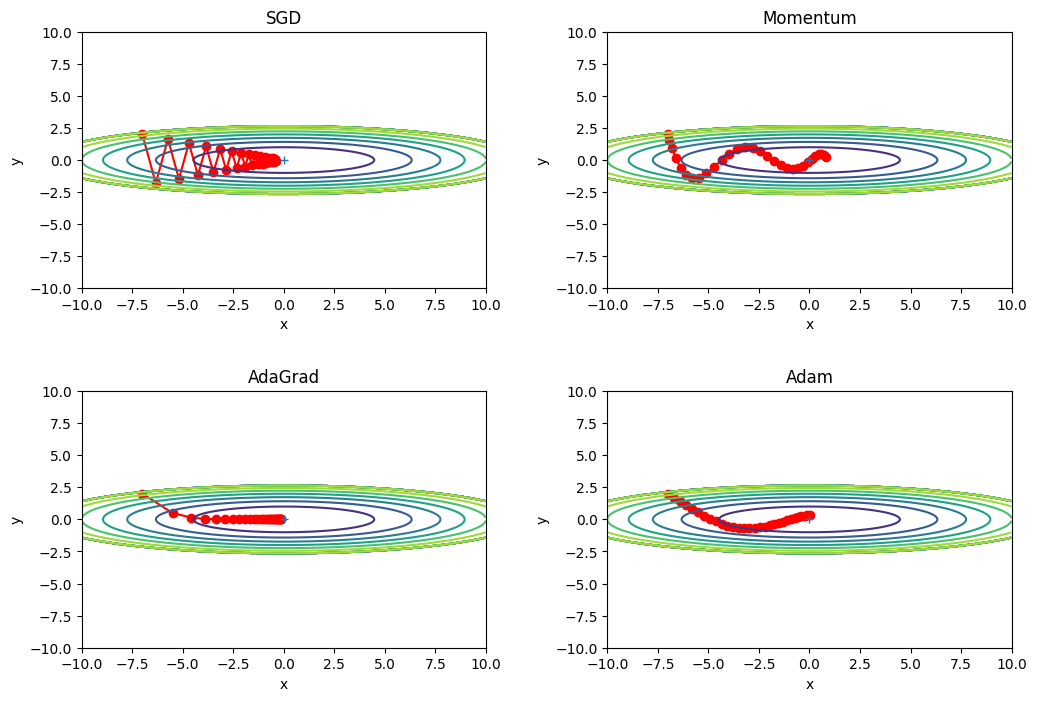

<Figure size 640x480 with 0 Axes>

In [ ]:
%run ch06/optimizer_compare_naive.py # !python 말고 %run을 사용하니까 그래프가 잘 나옴

## 6.1.8 MNIST 데이터셋으로 본 갱신 방법 비교

Converting train-images-idx3-ubyte.gz to NumPy Array ...
Done
Converting train-labels-idx1-ubyte.gz to NumPy Array ...
Done
Converting t10k-images-idx3-ubyte.gz to NumPy Array ...
Done
Converting t10k-labels-idx1-ubyte.gz to NumPy Array ...
Done
Creating pickle file ...
Done!
===========iteration:0===========
SGD:2.308652528725101
Momentum:2.375092138841908
AdaGrad:2.1416068626409848
Adam:2.10294196891647
===========iteration:100===========
SGD:1.341359208513613
Momentum:0.28729372353246374
AdaGrad:0.0974298502126143
Adam:0.2222447381778263
===========iteration:200===========
SGD:0.7264987261884237
Momentum:0.18905332276976966
AdaGrad:0.07623833206409286
Adam:0.11699575879866819
===========iteration:300===========
SGD:0.5027821394004828
Momentum:0.13567387494613145
AdaGrad:0.04831320999089365
Adam:0.07068243330981613
===========iteration:400===========
SGD:0.4095672997358046
Momentum:0.23795441212189306
AdaGrad:0.11199252049765512
Adam:0.16400399720490447
===========iteration:500======

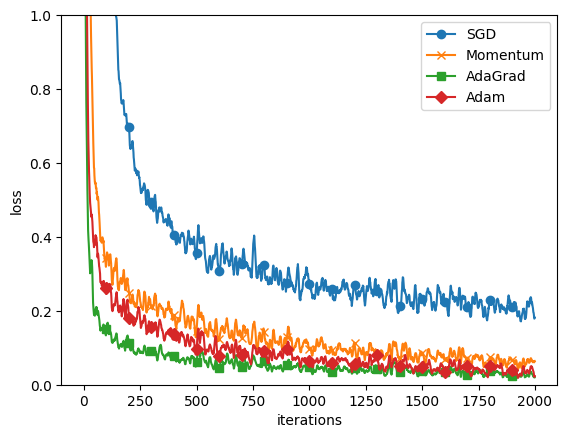

<Figure size 640x480 with 0 Axes>

In [ ]:
%run ch06/optimizer_compare_mnist.py

# 6.2 가중치의 초깃값
## 6.2.1 초깃값을 0으로 하면?
### 가중치 감소 weight decay
- 가중치 매개변수의 값이 작아지도록 학습하는 방법, 과대적합이 일어나지 않게 함
- 지금까지는 정규분포에서 생성되는 값을 0.01배 한 값을 사용함

### 초깃값을 0으로 설정하면?
- (정확히는 가중치를 균일한 값으로 설정하지 않는 것)
- 모든 가중치가 똑같이 갱신되기 때문!

## 6.2.2 은닉층의 활성화값 분포

- 활성화 함수로 시그모이드 함수를 사용하는 5층 신경망에 무작위로 생성한 입력데이터를 흘림
- 각층의 활성화값 분포를 히스토그램으로 그림


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def sigmoid(x):
  return 1 / (1 + np.exp(-x))

x = np.random.randn(1000, 100) # 1000개의 데이터
node_num = 100         # 각 은닉층의 노드(뉴런) 수
hidden_layer_size = 5  # 은닉층이 5개
activations = {}       # 이곳에 활성화 결과(활성화값)를 저장

for i in range(hidden_layer_size):
  if i != 0:
    x = activations[i-1]
  w = np.random.randn(node_num, node_num) * 1
  a = np.dot(x, w)
  z = sigmoid(a)
  activations[i] = z

- 층 5개
- 각 층의 뉴런 100개씩
- 1000개의 데이터 균등 생성

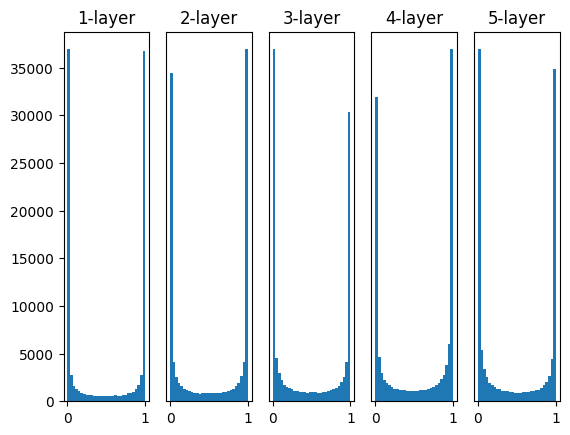

In [ ]:
# 히스토그램 그리기
for i, a in activations.items():
  plt.subplot(1, len(activations), i+1)
  plt.title(str(i+1) + "-layer")
  if i != 0: plt.yticks([], [])
  plt.hist(a.flatten(), 30, range=(0,1))
plt.show()

각 층의 활성화 값들이 0,1에 치우쳐 분포
### 기울기 소실 gradient vanishing
- 시그모이드 함수는 출력이 0, 1에 가까워지면, 미분이 0에 다가감.
- 그래서 0,1에 분포하면, 역전파의 기울기 값이 작아지다가 사라짐

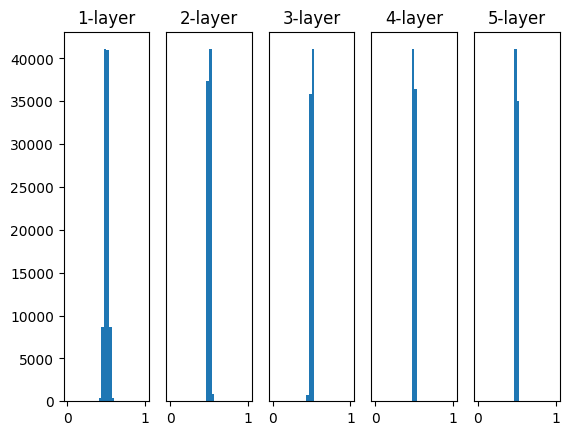

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def sigmoid(x):
  return 1 / (1 + np.exp(-x))

x = np.random.randn(1000, 100) # 1000개의 데이터
node_num = 100         # 각 은닉층의 노드(뉴런) 수
hidden_layer_size = 5  # 은닉층이 5개
activations = {}       # 이곳에 활성화 결과(활성화값)를 저장

for i in range(hidden_layer_size):
  if i != 0:
    x = activations[i-1]
  w = np.random.randn(node_num, node_num) * 0.01 # 0.01로 조정
  a = np.dot(x, w)
  z = sigmoid(a)
  activations[i] = z

# 히스토그램 그리기
for i, a in activations.items():
  plt.subplot(1, len(activations), i+1)
  plt.title(str(i+1) + "-layer")
  if i != 0: plt.yticks([], [])
  plt.hist(a.flatten(), 30, range=(0,1))
plt.show()

가중치의 표준편차를 0.01로 바꿔 같은 실험을 반복
- 값들이 0.5에 치우쳐져 있음
### 표현력을 제한한다는 문제 발생

### Xavier 초깃값
- 사비에르 글로로트와 요슈아 벤지오의 논문에서 권장
- 앞 계층의 노드가 n개라면 표준편차가 $\frac{1}{\sqrt h}$인 분포를 사용

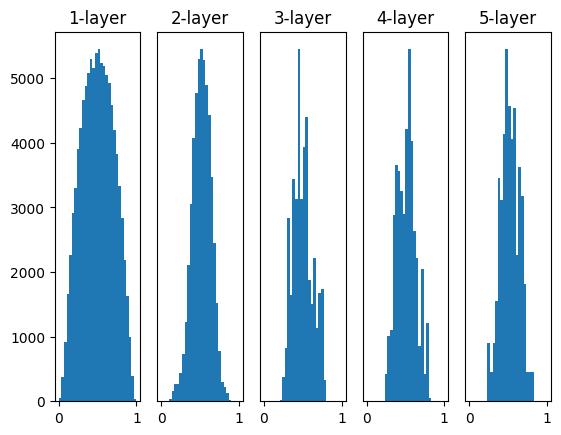

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def sigmoid(x):
  return 1 / (1 + np.exp(-x))

x = np.random.randn(1000, 100) # 1000개의 데이터
node_num = 100         # 각 은닉층의 노드(뉴런) 수
hidden_layer_size = 5  # 은닉층이 5개
activations = {}       # 이곳에 활성화 결과(활성화값)를 저장

for i in range(hidden_layer_size):
  if i != 0:
    x = activations[i-1]
  w = np.random.randn(node_num, node_num) / np.sqrt(node_num)
  a = np.dot(x, w)
  z = sigmoid(a)
  activations[i] = z

# 히스토그램 그리기
for i, a in activations.items():
  plt.subplot(1, len(activations), i+1)
  plt.title(str(i+1) + "-layer")
  if i != 0: plt.yticks([], [])
  plt.hist(a.flatten(), 30, range=(0,1))
plt.show()

앞 선 결과들보다는 확실히 넓게 분포됨
- 갈 수록 일그러지는 문제는 tanh 함수를 활성화 함수로 쓰면 해결되기는 한다.

## 6.2.3 ReLU를 사용할 때의 가중치 초깃값
### He 초깃값
- 카이밍 히 (Kaiming He)의 이름을 땀
- 앞 계층의 노드가 n개라면 표준편차가 $\sqrt\frac{2}{h}$인 분포를 사용

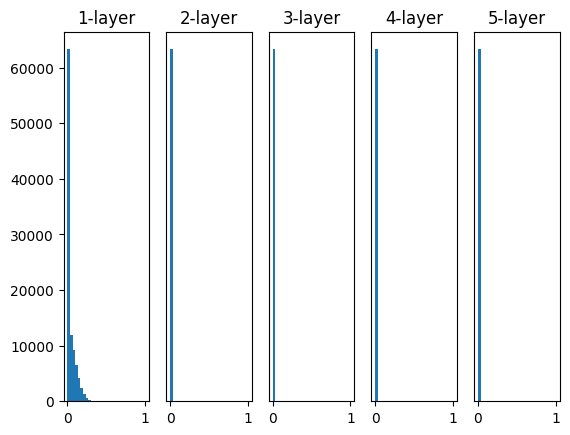

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def ReLU(x):
  return np.maximum(0, x)

x = np.random.randn(1000, 100) # 1000개의 데이터
node_num = 100         # 각 은닉층의 노드(뉴런) 수
hidden_layer_size = 5  # 은닉층이 5개
activations = {}       # 이곳에 활성화 결과(활성화값)를 저장

for i in range(hidden_layer_size):
  if i != 0:
    x = activations[i-1]
  w = np.random.randn(node_num, node_num) * 0.01 # 0.01로 조정
  a = np.dot(x, w)
  z = ReLU(a)
  activations[i] = z

# 히스토그램 그리기
for i, a in activations.items():
  plt.subplot(1, len(activations), i+1)
  plt.title(str(i+1) + "-layer")
  if i != 0: plt.yticks([], [])
  plt.hist(a.flatten(), 30, range=(0,1))
plt.show()

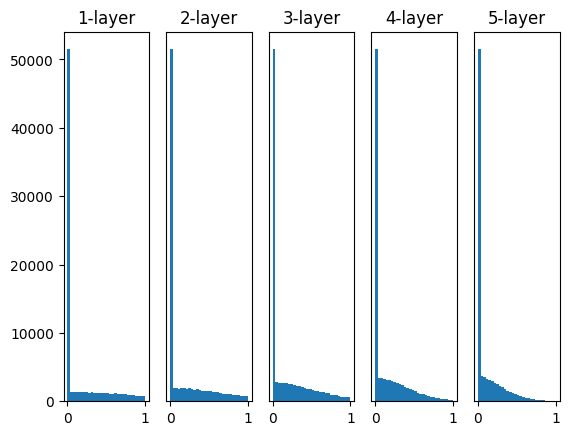

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def ReLU(x):
  return np.maximum(0, x)

x = np.random.randn(1000, 100) # 1000개의 데이터
node_num = 100         # 각 은닉층의 노드(뉴런) 수
hidden_layer_size = 5  # 은닉층이 5개
activations = {}       # 이곳에 활성화 결과(활성화값)를 저장

for i in range(hidden_layer_size):
  if i != 0:
    x = activations[i-1]
  w = np.random.randn(node_num, node_num) / np.sqrt(node_num)
  a = np.dot(x, w)
  z = ReLU(a)
  activations[i] = z

# 히스토그램 그리기
for i, a in activations.items():
  plt.subplot(1, len(activations), i+1)
  plt.title(str(i+1) + "-layer")
  if i != 0: plt.yticks([], [])
  plt.hist(a.flatten(), 30, range=(0,1))
plt.show()

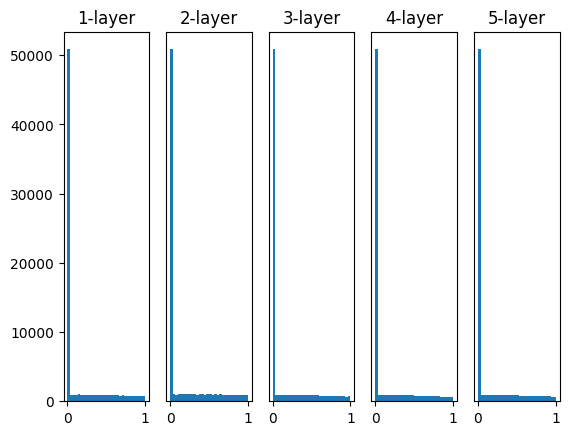

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def ReLU(x):
  return np.maximum(0, x)

x = np.random.randn(1000, 100) # 1000개의 데이터
node_num = 100         # 각 은닉층의 노드(뉴런) 수
hidden_layer_size = 5  # 은닉층이 5개
activations = {}       # 이곳에 활성화 결과(활성화값)를 저장

for i in range(hidden_layer_size):
  if i != 0:
    x = activations[i-1]
  w = np.random.randn(node_num, node_num) / np.sqrt(node_num) * np.sqrt(2)
  a = np.dot(x, w)
  z = ReLU(a)
  activations[i] = z

# 히스토그램 그리기
for i, a in activations.items():
  plt.subplot(1, len(activations), i+1)
  plt.title(str(i+1) + "-layer")
  if i != 0: plt.yticks([], [])
  plt.hist(a.flatten(), 30, range=(0,1))
plt.show()

### 활성화 함수로 ReLU를 사용한 경우의 가중치 초깃값에 따른 활성화값 분포 변화

1. 표준편차가 0.01인 정규분포를 사용
- 각 층의 활성화 값들이 매우 작은 값이라 분포가 고르지 못함 (기울기가 너무 작아서)
2. Xavier 초깃값을 사용
- 층이 깊어지면서 치우침이 조금씩 커짐, 기울기 소실 문제
3. He 초깃값을 사용
- 모든 층에서 균일하게 분포

## 6.2.4 MNIST 데이터셋으로 본 가중치 초깃값 비교

- He 초깃값이 학습이 제일 잘 이루어짐

===========iteration:0===========
std=0.01:2.3025339232288426
Xavier:2.294416105910715
He:2.3270579865440206
===========iteration:100===========
std=0.01:2.302752355860167
Xavier:2.2606378636953153
He:1.6911784129089409
===========iteration:200===========
std=0.01:2.3020589052522524
Xavier:2.161837261300425
He:0.9825464079721322
===========iteration:300===========
std=0.01:2.3025053748466098
Xavier:1.982344971665778
He:0.5834933370367728
===========iteration:400===========
std=0.01:2.3052331726889745
Xavier:1.5577570440267976
He:0.5632675935895013
===========iteration:500===========
std=0.01:2.304180602404447
Xavier:1.1010314829247823
He:0.37044147763609137
===========iteration:600===========
std=0.01:2.297712353314571
Xavier:0.7311094661489246
He:0.4169993823632955
===========iteration:700===========
std=0.01:2.3009777097646236
Xavier:0.6016633560504345
He:0.2958792077977979
===========iteration:800===========
std=0.01:2.3088895359746733
Xavier:0.6469884554333313
He:0.3921409792206894

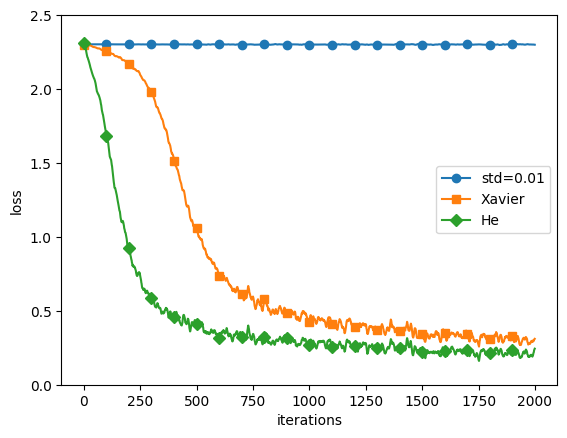

<Figure size 640x480 with 0 Axes>

In [ ]:
%run ch06/weight_init_compare.py

# 6.3 배치 정규화 Batch Normalization
- 각 층이 활성화를 퍼뜨리도록 강제하는 방법

## 6.3.1 배치 정규화 알고리즘

### 배치 정규화의 이점
1. 학습 속도 개선
2. 초깃값에 크게 의존 하지 않음
3. 과대적합 억제

### 배치 정규화 (Batch Norm) 계층
- 데이터 분포를 정규화하는 계층
- 데이터 분포가 평균이 0, 분산이 1이 되도록 정규화함

$$\mu_B \leftarrow \frac{1}{m}\sum_{i=1}^{m} x_i$$

$$\sigma_B^2 \leftarrow \frac{1}{m}\sum_{i=1}^{m} (x_i - \mu_B)^2$$

$$\hat x_i \leftarrow \frac{x_i - \mu_B}{\sqrt{\sigma^2_B + \epsilon}}$$

미니배치 $B = (x_1, x_2, ... , x_m)$
- $\mu_B$ : 표본평균
- $\sigma_B^2 $ : 표본분산
- $\hat x_i$ : 평균이 0, 분산이 1인 정규분포 - N(0,1)
- $\epsilon$ : 엡실론, 작은 값으로 0으로 나누는 것을 방지하는 역할

배치 정규화 계층마다 고유한 확대(Scale)와 이동(shift)을 수행

$$y_i \leftarrow \gamma \hat x_i+ \beta$$

- $\gamma$ : 확대
- $\beta$ : 이동

## 6.3.2 배치 정규화의 효과

epoch:0 | 0.113 - 0.121
epoch:1 | 0.118 - 0.179
epoch:2 | 0.126 - 0.364
epoch:3 | 0.132 - 0.477
epoch:4 | 0.142 - 0.554
epoch:5 | 0.153 - 0.606
epoch:6 | 0.167 - 0.652
epoch:7 | 0.177 - 0.692
epoch:8 | 0.188 - 0.716
epoch:9 | 0.218 - 0.746
epoch:10 | 0.229 - 0.779
epoch:11 | 0.237 - 0.794
epoch:12 | 0.243 - 0.806
epoch:13 | 0.257 - 0.818
epoch:14 | 0.268 - 0.829
epoch:15 | 0.273 - 0.854
epoch:16 | 0.291 - 0.859
epoch:17 | 0.301 - 0.87
epoch:18 | 0.317 - 0.881
epoch:19 | 0.321 - 0.885


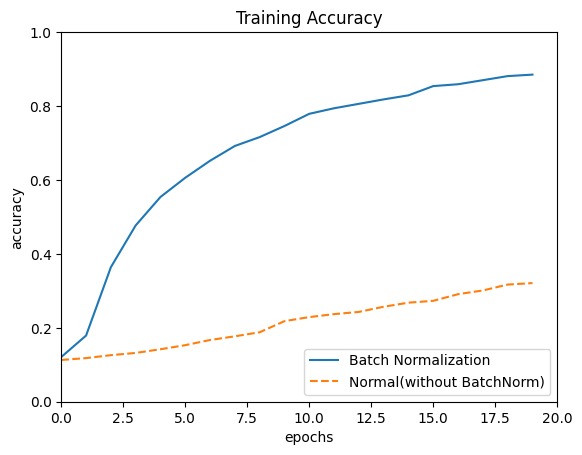

<Figure size 640x480 with 0 Axes>

In [ ]:
%run ch06/batch_norm_test.py

가중치 초깃값의 표준편차를 다양하게 한 경우들

============== 1/16 ==============
epoch:0 | 0.093 - 0.097


/content/deep-learning-from-scratch/common/layers.py:62: RuntimeWarning: overflow encountered in dot
  dx = np.dot(dout, self.W.T)
/content/deep-learning-from-scratch/common/layers.py:57: RuntimeWarning: overflow encountered in dot
  out = np.dot(self.x, self.W) + self.b
/content/deep-learning-from-scratch/common/layers.py:57: RuntimeWarning: invalid value encountered in dot
  out = np.dot(self.x, self.W) + self.b
/content/deep-learning-from-scratch/common/multi_layer_net_extend.py:105: RuntimeWarning: overflow encountered in square
  weight_decay += 0.5 * self.weight_decay_lambda * np.sum(W**2)
/content/deep-learning-from-scratch/common/multi_layer_net_extend.py:105: RuntimeWarning: invalid value encountered in scalar multiply
  weight_decay += 0.5 * self.weight_decay_lambda * np.sum(W**2)
/content/deep-learning-from-scratch/common/layers.py:63: RuntimeWarning: invalid value encountered in dot
  self.dW = np.dot(self.x.T, dout)


epoch:1 | 0.097 - 0.105
epoch:2 | 0.097 - 0.114
epoch:3 | 0.097 - 0.136
epoch:4 | 0.097 - 0.154
epoch:5 | 0.097 - 0.182
epoch:6 | 0.097 - 0.199
epoch:7 | 0.097 - 0.224
epoch:8 | 0.097 - 0.234
epoch:9 | 0.097 - 0.248
epoch:10 | 0.097 - 0.261
epoch:11 | 0.097 - 0.28
epoch:12 | 0.097 - 0.294
epoch:13 | 0.097 - 0.311
epoch:14 | 0.097 - 0.329
epoch:15 | 0.097 - 0.338
epoch:16 | 0.097 - 0.352
epoch:17 | 0.097 - 0.36
epoch:18 | 0.097 - 0.379
epoch:19 | 0.097 - 0.387
============== 2/16 ==============
epoch:0 | 0.097 - 0.101
epoch:1 | 0.097 - 0.101
epoch:2 | 0.097 - 0.118
epoch:3 | 0.097 - 0.139
epoch:4 | 0.097 - 0.171
epoch:5 | 0.097 - 0.192
epoch:6 | 0.097 - 0.221
epoch:7 | 0.097 - 0.232
epoch:8 | 0.097 - 0.254
epoch:9 | 0.097 - 0.28
epoch:10 | 0.097 - 0.3
epoch:11 | 0.097 - 0.32
epoch:12 | 0.097 - 0.335
epoch:13 | 0.097 - 0.357
epoch:14 | 0.097 - 0.382
epoch:15 | 0.097 - 0.388
epoch:16 | 0.097 - 0.413
epoch:17 | 0.097 - 0.436
epoch:18 | 0.097 - 0.453
epoch:19 | 0.097 - 0.473
============== 

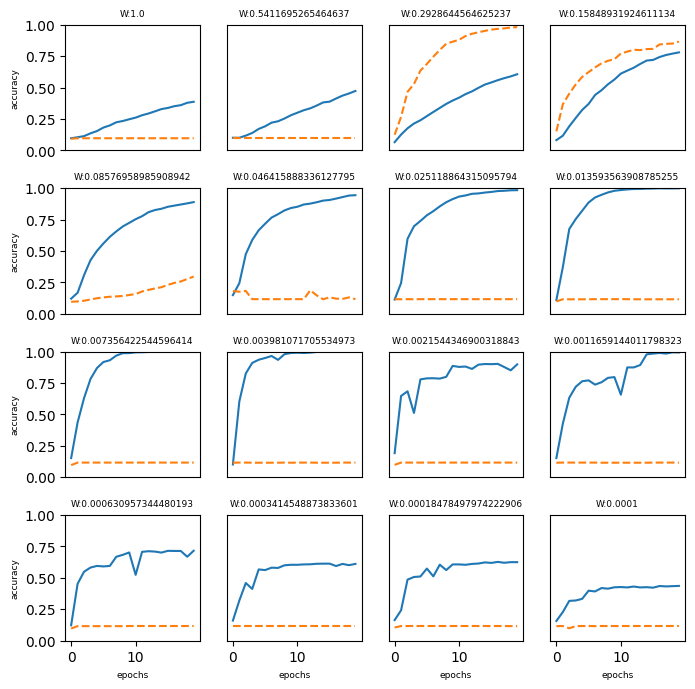

<Figure size 640x480 with 0 Axes>

In [ ]:
%run ch06/batch_norm_test_multi.py

# 6.4 바른 학습을 위해
## 6.4.1 과대적합
- 신경망이 지나치게 적응되어 그 외의 데이터에는 제대로 대응하지 못하는 상태

과대적합이 일어나는 경우
1. 매개변수가 많고 표현력이 높은 모델
2. 훈련 데이터가 적은 경우

> 일부러 학습데이터를 줄이고, 매개변수를 늘려서 과대적합 재현하기

- 60000개의 mnist 데이터셋 중 300개만 사용
- 7층 신경망

epoch:0, train acc:0.14, test acc:0.1267
epoch:1, train acc:0.14666666666666667, test acc:0.1397
epoch:2, train acc:0.17333333333333334, test acc:0.1566
epoch:3, train acc:0.21, test acc:0.17
epoch:4, train acc:0.25, test acc:0.2012
epoch:5, train acc:0.2633333333333333, test acc:0.2197
epoch:6, train acc:0.31333333333333335, test acc:0.2526
epoch:7, train acc:0.35, test acc:0.2812
epoch:8, train acc:0.3566666666666667, test acc:0.2968
epoch:9, train acc:0.3933333333333333, test acc:0.3122
epoch:10, train acc:0.4166666666666667, test acc:0.3238
epoch:11, train acc:0.43666666666666665, test acc:0.3396
epoch:12, train acc:0.5066666666666667, test acc:0.3782
epoch:13, train acc:0.5066666666666667, test acc:0.3935
epoch:14, train acc:0.56, test acc:0.4328
epoch:15, train acc:0.5766666666666667, test acc:0.4543
epoch:16, train acc:0.6166666666666667, test acc:0.4712
epoch:17, train acc:0.6366666666666667, test acc:0.5015
epoch:18, train acc:0.6766666666666666, test acc:0.5278
epoch:19, trai

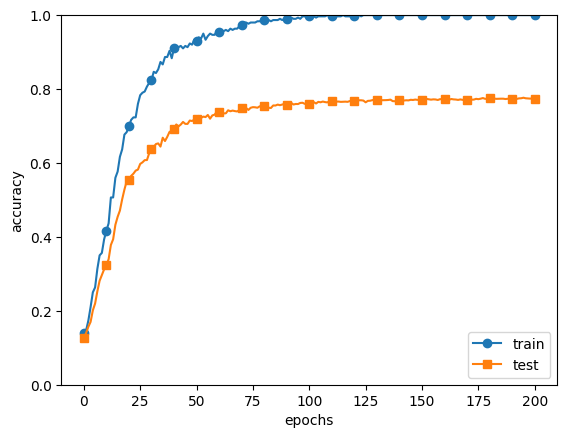

<Figure size 640x480 with 0 Axes>

In [ ]:
%run ch06/overfit.py

훈련데이터에 대해서는 100epoch부터 거의 100%
- 하지만 시험데이터는 그렇지 못함

> 훈련 데이터에 적응해버린 결과

## 6.4.2 가중치 감소 Weight decay
- 큰 가중치에 그에 상응하는 페널티를 부과
- 가중치가 너무 커지는 현상을 억제 하는 거임

### L2 노름 norm (제곱 노룸)
L2 노름에 의한 가중치 감소는 $\frac{1}{2}\lambda W^2$

- $\lambda$ : 정규화의 세기를 조절하는 하이퍼파라미터
- 가중치 감소는 모든 가중치 각각의 손실 함수에 $\frac{1}{2}\lambda W^2$을 더함
- 오차역전파법에 따른 결과에 정규화 항을 미분한 $\lambda W$를 더함


epoch:0, train acc:0.11, test acc:0.0994
epoch:1, train acc:0.12666666666666668, test acc:0.1133
epoch:2, train acc:0.16333333333333333, test acc:0.1317
epoch:3, train acc:0.18666666666666668, test acc:0.1464
epoch:4, train acc:0.20666666666666667, test acc:0.1619
epoch:5, train acc:0.24, test acc:0.1722
epoch:6, train acc:0.27, test acc:0.1846
epoch:7, train acc:0.27666666666666667, test acc:0.1946
epoch:8, train acc:0.32, test acc:0.2086
epoch:9, train acc:0.33666666666666667, test acc:0.2275
epoch:10, train acc:0.39, test acc:0.2451
epoch:11, train acc:0.4033333333333333, test acc:0.26
epoch:12, train acc:0.43, test acc:0.2745
epoch:13, train acc:0.4533333333333333, test acc:0.2822
epoch:14, train acc:0.4666666666666667, test acc:0.3045
epoch:15, train acc:0.47, test acc:0.3187
epoch:16, train acc:0.4666666666666667, test acc:0.3246
epoch:17, train acc:0.48333333333333334, test acc:0.3496
epoch:18, train acc:0.5166666666666667, test acc:0.3644
epoch:19, train acc:0.5233333333333333,

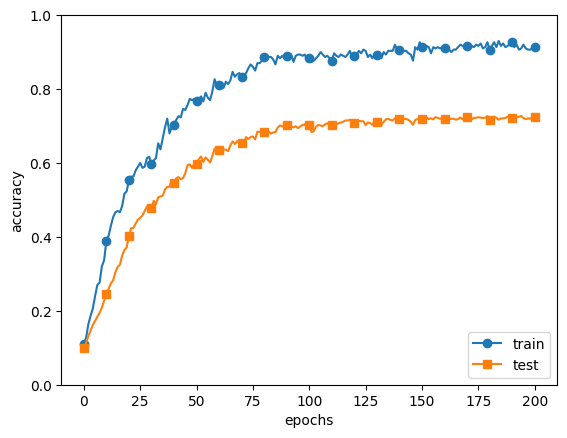

<Figure size 640x480 with 0 Axes>

In [ ]:
%run ch06/overfit_weight_decay.py

서로간의 차이가 줄어든걸 볼 수 있음, 100%에 도달하지 못함
- 과대적합이 억제 되었다.

## 6.4.3 드롭아웃 Dropout
신경망이 복잡해지면 가중치 감소만으로 대응하기 어려움

- 드롭아웃은 뉴런을 임의로 삭제하면서 학습하는 기법
- 훈련할때 : 무작위로 뉴런 삭제
- 시험할때 : 모든 뉴런 사용, 각 뉴런의 출력에 삭제 안 한 비율을 곱하여 출력 (안 해도 됨)

In [ ]:
class Dropout:
  def __init__ (self, dropout_ratio=0.5):
    self.dropout_ratio = dropout_ratio
    self.mask = None

  def forward(self, x, train_flg=True):
    if train_flg:
      self.mask = np.random.rand(*x.shape) > self.dropout_ratio
      return x * self.mask
    else:
      return x * (1.0 - self.dropout_ratio)

  def backward(self, dout):
    return dout * self.mask

훈련 시에 순전파 때마다 self.mask에 삭제할 뉴런을 False로 표시
- self.mask에는 x와 형상이 같은 배열을 무작위로 생성하고, 그 값이 drpoout_ratio보다 크면 True
- 훈련할때 순전파때 끈 뉴런은 역전파 때도 끄는게 포인트

train loss:2.3156052156466096
=== epoch:1, train acc:0.08333333333333333, test acc:0.1044 ===
train loss:2.307326625820947
train loss:2.326903232489177
train loss:2.314644818856095
=== epoch:2, train acc:0.08666666666666667, test acc:0.1041 ===
train loss:2.2929376729421564
train loss:2.310580825210576
train loss:2.3069435296106398
=== epoch:3, train acc:0.08666666666666667, test acc:0.1038 ===
train loss:2.308721299942894
train loss:2.302628896645567
train loss:2.3109316989001103
=== epoch:4, train acc:0.08666666666666667, test acc:0.1057 ===
train loss:2.2998290862317248
train loss:2.3043857618924193
train loss:2.3010519841113606
=== epoch:5, train acc:0.09666666666666666, test acc:0.1069 ===
train loss:2.3008157697755736
train loss:2.31984472273449
train loss:2.3215399604010893
=== epoch:6, train acc:0.11, test acc:0.1095 ===
train loss:2.3059626191642506
train loss:2.303367796551502
train loss:2.3071221802501043
=== epoch:7, train acc:0.10666666666666667, test acc:0.109 ===
train l

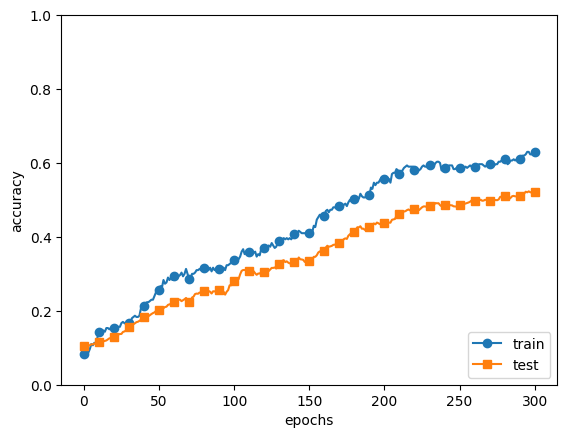

<Figure size 640x480 with 0 Axes>

In [ ]:
%run ch06/overfit_dropout.py

드롭아웃을 이용하니 훈련 데이터와 시험 데이터에 대한 정확도 차이가 줄어듬

### 앙상블 학습 ensemble learning

- 개별적으로 학습시킨 여러 모델의 출력을 평균내어 추론하는 방식
- 예를 들자면 같은(비슷한) 신경망을 5개를 따로따로 학습시키고, 시험때는 5개의 출력을 평균내어 답하는 것
- 드롭아웃과 밀접함

# 6.5 적절한 하이퍼파라미터 값 찾기
### 하이퍼 파라미터
- 각 층의 뉴런 수
- 배치 크기
- 매개변수 갱신시의 학습률, 가중치 감소

## 6.5.1 검증 데이터 validation data
- 훈련 데이터 : 매개변수 학습
- 검증 데이터 : 하이퍼파라미터 성능 평가
- 시험 데이터 : 신경망의 범용 성능 평가

```

(x_train, t_train), (x_test, t_test) = load_mnist()

# 훈련 데이터를 뒤섞는다.
x_train, t_train = shuffle_dataset(x_train, t_train)

# 20%를 검증 데이터로 분할
validation_rate = 0.20
validation_num = int(x_train.shape[0] * validation_rate)

x_val = x_train[:validation_num]
t_val = t_train[:validation_num]
x_train = x_train[ validation_num: ]
t_train = t_train[validation_num: ]

```




## 6.5.2 하이퍼파라미터 최적화

하이퍼파라미터의 최적값이 존재하는 범위를 조금씩 줄여감

대략적으로 0.001~1000 같이 10의 거듭제곱 꼴로 범위를 지정함
- 로그 스케일로 지정한다고 함

하이퍼파라미터 최적화는 매우 오래 걸림
- 1회 평가에 걸리는 시간을 줄이는 것이 효과적

### 단계

### 0단계
- 하이퍼파라미터 값의 범위 설정
### 1단계
- 설정된 범위에서 하이퍼파라미터의 값을 무작위 추출
### 2단계
- 1단계에서 샘플링한 하이퍼파라미터 값을 사용하여 학습하고, 검증 데이터로 정확도를 평가함
### 3단계
- 1단계와 2단계를 반복하여, 그 정확도와 결과를 보고 하이퍼 파라미터의 범위를 좁힘

## 6.5.3 하이퍼파라미터 최적화 구현하기

- MNIST 데이터셋을 이용하여 하이퍼파라미터 최적화
- 학습률 ($10^{-6}$ ~ $10^{-2}$)
- 가중치 감소 계수 ($10^{-8}$ ~ $10^{-4}$)

```
weight_decay = 10 ** np.random.uniform(-8, -4)
lr = 10 ** np.random.uniform(-6, -2)

```

이렇게 적절한 값이 위치한 범위를 좁혀가다가 특정단계에서 최종 하이퍼파라미터값 하나를 선택

아래는 코드 ch06/hyperparameter_optimization.py
- optimization_trial = 20 으로 바꾸어서 실행함



In [ ]:
# coding: utf-8
import sys, os
sys.path.append(os.path.join(os.path.dirname(__file__), '..'))

import numpy as np
import matplotlib.pyplot as plt
from dataset.mnist import load_mnist
from common.multi_layer_net import MultiLayerNet
from common.util import shuffle_dataset
from common.trainer import Trainer

(x_train, t_train), (x_test, t_test) = load_mnist(normalize=True)

# 결과를 빠르게 얻기 위해 훈련 데이터를 줄임
x_train = x_train[:500]
t_train = t_train[:500]

# 20%를 검증 데이터로 분할
validation_rate = 0.20
validation_num = int(x_train.shape[0] * validation_rate)
x_train, t_train = shuffle_dataset(x_train, t_train)
x_val = x_train[:validation_num]
t_val = t_train[:validation_num]
x_train = x_train[validation_num:]
t_train = t_train[validation_num:]


def __train(lr, weight_decay, epocs=50):
    network = MultiLayerNet(input_size=784, hidden_size_list=[100, 100, 100, 100, 100, 100],
                            output_size=10, weight_decay_lambda=weight_decay)
    trainer = Trainer(network, x_train, t_train, x_val, t_val,
                      epochs=epocs, mini_batch_size=100,
                      optimizer='sgd', optimizer_param={'lr': lr}, verbose=False)
    trainer.train()

    return trainer.test_acc_list, trainer.train_acc_list


# 하이퍼파라미터 무작위 탐색======================================
optimization_trial = 20
results_val = {}
results_train = {}
for _ in range(optimization_trial):
    # 탐색한 하이퍼파라미터의 범위 지정===============
    weight_decay = 10 ** np.random.uniform(-8, -4)
    lr = 10 ** np.random.uniform(-6, -2)
    # ================================================

    val_acc_list, train_acc_list = __train(lr, weight_decay)
    print("val acc:" + str(val_acc_list[-1]) + " | lr:" + str(lr) + ", weight decay:" + str(weight_decay))
    key = "lr:" + str(lr) + ", weight decay:" + str(weight_decay)
    results_val[key] = val_acc_list
    results_train[key] = train_acc_list

# 그래프 그리기========================================================
print("=========== Hyper-Parameter Optimization Result ===========")
graph_draw_num = 20
col_num = 5
row_num = int(np.ceil(graph_draw_num / col_num))
i = 0

plt.figure(figsize=(10, 8))

for key, val_acc_list in sorted(results_val.items(), key=lambda x:x[1][-1], reverse=True):
    print("Best-" + str(i+1) + "(val acc:" + str(val_acc_list[-1]) + ") | " + key)

    plt.subplot(row_num, col_num, i+1)
    plt.title("Best-" + str(i+1))
    plt.ylim(0.0, 1.0)
    if i % 5: plt.yticks([])
    plt.xticks([])
    x = np.arange(len(val_acc_list))
    plt.plot(x, val_acc_list)
    plt.plot(x, results_train[key], "--")
    i += 1

    if i >= graph_draw_num:
        break

plt.subplots_adjust(wspace=0.2, hspace=0.3)
plt.show()


val acc:0.08 | lr:1.6850322579543975e-05, weight decay:4.759075169674966e-08
val acc:0.15 | lr:0.0003944015881405815, weight decay:1.350135143852014e-07
val acc:0.16 | lr:0.00031443403976252736, weight decay:2.59624779512005e-07
val acc:0.1 | lr:0.0002158136542106452, weight decay:9.419803564277654e-05
val acc:0.16 | lr:8.442015200500984e-05, weight decay:6.657087550920884e-05
val acc:0.22 | lr:0.000986504682768122, weight decay:1.0018661347244636e-07
val acc:0.61 | lr:0.0037615954709616967, weight decay:4.87950968014477e-05
val acc:0.09 | lr:5.456837524612926e-06, weight decay:3.7918798223850847e-05
val acc:0.09 | lr:7.0550441019186005e-06, weight decay:3.082524311487903e-08
val acc:0.21 | lr:0.0006980848574508968, weight decay:1.3050747876010276e-07
val acc:0.12 | lr:0.00013034302203634407, weight decay:2.022213025154058e-07
val acc:0.07 | lr:0.00011934126253099466, weight decay:7.48890659509332e-08
val acc:0.1 | lr:1.09865758168074e-06, weight decay:3.967449864316708e-06
val acc:0.7

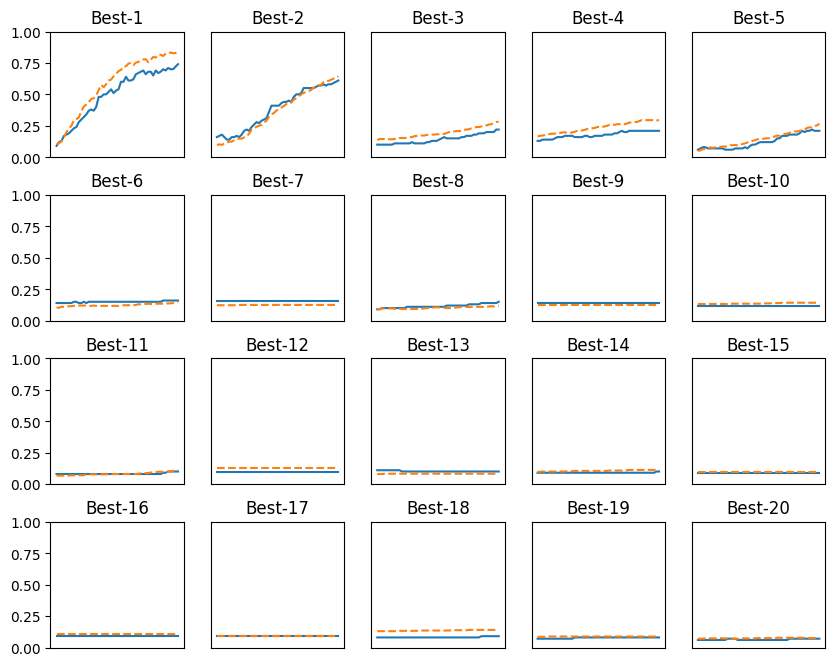

<Figure size 640x480 with 0 Axes>

In [3]:
%run ch06/hyperparameter_optimization.py